# 实验七：图卷积网络与 Cora 论文分类

本次研究两个信息来源：论文自身的词特征，以及论文之间的引用关系。目标是理解邻居聚合和 GCN，完成有证据的对照研究。

从 [LINQS 下载 Cora（cora.tgz）](https://linqs-data.soe.ucsc.edu/public/lbc/cora.tgz)，将压缩包解到实验七目录，使 `cora/cora.content` 和 `cora/cora.cites` 位于 notebook 旁的 `cora/` 下。 数据字段与来源见[数据集说明](数据集说明.md)。

| 环节              | 检查点                         |
| ----------------- | ------------------------------ |
| Q1 数据与建图审查 | 用数据纠正两条错误说法         |
| Q2 自环与归一化   | 手算、稠密／稀疏核验、两跳传播 |
| Q3 GCN 与训练检查 | 完成模型，解释训练标签掩码     |
| Q4 MLP 与 GCN     | 两种子基线与验证比较           |
| Q5 标签数量研究   | 嵌套划分、实验方案、证据表     |
| Q6 引用缺失研究   | 重建归一化、重复训练与解释     |
| Q7 自己做一次调参 | 提出假设、修改参数、比较结果   |


## 0 · 环境与共同约定

一些基本的配置约定如下，和之前不同的是，这里用一个 `CONFIG: dict` 字典来存储不同的配置字段，有利于后面代码的简洁 ~~（希望同学们不要忘记字典的取用方法，也不要忘记一些字段的含义）~~

代码段中专门用了一个 `TODO()` 用于标记需要填写的内容，没有再采用注释的方式了，同学们注意一下即可。

- 固定训练池每类 20 节点，共 140；验证 500；测试 2,068。标签数量实验只从训练池取子集；
- 图为无向引用关系，去重后加自环；节点特征按行归一化。训练时看见全图，损失只使用已启用训练标签；
- 两层模型为 1433→16→7，无偏置，激活函数使用 ReLU；输入与隐藏特征 dropout=0.5，输出 logits 使用交叉熵损失；
- Adam，lr=0.01，weight_decay=0.0005，200 轮；每轮一次全图更新，模型种子 42、2026；


In [1]:
import os
import platform
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython import get_ipython
from lab_utils import (
    case_key,
    fit_model,
    graph_audit,
    identity_operator,
    normalize_features,
    parameter_counts,
    plot_factor,
    plot_graph_audit,
    plot_history,
    print_validation_table,
    propagate,
    read_raw_cora,
    save_split,
    seed_everything,
    self_edges,
    snapshot,
    sparse_operator,
    stratified_split,
    summarize_cases,
)
from torch import nn
from torch.nn import functional as F

if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
torch.set_num_threads(min(4, os.cpu_count() or 1))

DEVICE = torch.device("cpu")
# DEVICE = torch.device("cuda") # 对应 GPU 版本
# DEVICE = torch.device("mps") # 对应 M 系列芯片

# 配置字典，统一整理方便调用
CONFIG = {
    "version": "GCN-160min",
    "epochs": int(os.environ.get("LAB7_EPOCHS", "200")),
    "hidden": 16,
    "dropout": 0.5,
    "lr": 0.01,
    "weight_decay": 0.0005,
    "seeds": [42, 2026],
    "split_seed": 42,
    "label_seed": 2026,
    "edge_seed": 2026,
}
ENVIRONMENT = {
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "numpy": np.__version__,
    "matplotlib": matplotlib.__version__,
    "device": str(DEVICE),
    "machine": platform.machine(),
    "threads": torch.get_num_threads(),
}

OUTPUT_DIR = Path("输出_GCN")
OUTPUT_DIR.mkdir(exist_ok=True)
print(ENVIRONMENT)
print(CONFIG)


# 用法：把 TODO("题号") 整体替换为自己的表达式，不需要改这个函数。
# 每个小空只负责一个步骤；程序停下时，错误信息会指向尚未完成的题号。
def TODO(step):
    raise NotImplementedError(f"请先完成 {step}，将 TODO(...) 替换为自己的表达式")


{'python': '3.12.14', 'torch': '2.14.1', 'numpy': '2.5.3', 'matplotlib': '3.11.2', 'device': 'cpu', 'machine': 'arm64', 'threads': 4}
{'version': 'GCN-160min', 'epochs': 200, 'hidden': 16, 'dropout': 0.5, 'lr': 0.01, 'weight_decay': 0.0005, 'seeds': [42, 2026], 'split_seed': 42, 'label_seed': 2026, 'edge_seed': 2026}


## Q1 · 数据与建图审查

完成 `encode_cora` 函数，其功能是将 cora 数据集嵌入到我们的张量中，方便后续训练。每行论文记录含字符串 ID、1,433 个二值词特征、类别；每条引用记录为“被引用者、引用者”。

连续张量下标必须由 ID 映射得到。双向建图后去重，每个节点恰好添加一个自环。


In [2]:
def encode_cora(contents: list[list[str]], citations: list[tuple[str, ...]]):
    """返回 paper_ids、class_names、归一化特征 x、整数标签 y、双向边 edges。"""
    # contents 的一行：['论文ID', '0', '1', ..., '类别名']。
    # Q1.1：每行第 0 项就是论文 ID。写出提取所有 ID 的列表推导式。
    paper_ids = [row[0] for row in contents]
    assert len(paper_ids) == len(contents) and isinstance(paper_ids[0], str)
    assert len(set(paper_ids)) == len(paper_ids), "论文 ID 应唯一"
    # 映射的写法已给出，之后只能用这个映射将 ID 转成下标。
    id_to_idx = {paper_id: i for i, paper_id in enumerate(paper_ids)}

    # 固定类别顺序，避免每次运行得到不同的编码。
    class_names = sorted({row[-1] for row in contents})
    class_to_idx = {name: i for i, name in enumerate(class_names)}

    # Q1.2：类别在 row 的最后一项。填入该项，字典会把它转换为整数。
    label_ids = [class_to_idx[row[-1]] for row in contents]
    y = torch.tensor(label_ids, dtype=torch.long)

    # Q1.3：一行去掉首项 ID 与末项类别，剩下的才是词特征。填写切片。
    word_columns = [row[1:-1] for row in contents]
    x = torch.from_numpy(np.asarray(word_columns, dtype=np.float32))
    assert x.ndim == 2 and x.shape[0] == len(paper_ids)

    pairs = set()
    for cited, citing in citations:
        # Q1.4：用 id_to_idx 分别查询两个 ID，返回两个连续下标组成的元组。
        u, v = (id_to_idx[cited], id_to_idx[citing])
        pairs.add((u, v))

        # Q1.5：主实验允许双向传播，还要添加反向的下标对。
        pairs.add((v, u))

    # 用集合去重，并给每个节点添加一个自环；张量转换与排序已提供。
    pairs.update((i, i) for i in range(len(paper_ids)))
    edges = torch.tensor(sorted(pairs), dtype=torch.long).T.contiguous()
    return paper_ids, class_names, normalize_features(x), y, edges


{'undirected_edges': 5278, 'isolates': 0, 'components': 78, 'largest_component': 2485}
类别顺序: ['Case_Based', 'Genetic_Algorithms', 'Neural_Networks', 'Probabilistic_Methods', 'Reinforcement_Learning', 'Rule_Learning', 'Theory']


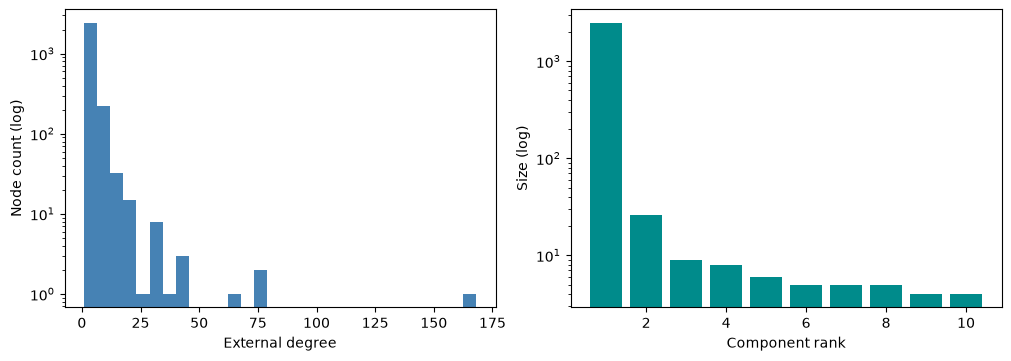

In [3]:
raw, citations = read_raw_cora()
paper_ids, class_names, x_cpu, y, edges_cpu = encode_cora(raw, citations)
assert x_cpu.shape == (2708, 1433) and edges_cpu.shape == (2, 13264)
assert y.dtype == torch.long and len(class_names) == 7
pairs = set(map(tuple, edges_cpu.T.tolist()))
assert len(pairs) == 13264 and all((j, i) in pairs for i, j in pairs)
assert sum(i == j for i, j in pairs) == 2708
audit = graph_audit(edges_cpu, len(y))
print(
    {
        key: value
        for key, value in audit.items()
        if key not in {"degree", "component_sizes"}
    }
)
print("类别顺序:", class_names)
fig = plot_graph_audit(audit)
plt.show()
split = stratified_split(y, seed=CONFIG["split_seed"])
train_idx, val_idx, test_idx = split["train"], split["val"], split["test"]
assert [len(train_idx), len(val_idx), len(test_idx)] == [140, 500, 2068]
assert torch.cat(list(split.values())).unique().numel() == 2708
save_split(split, paper_ids, class_names, OUTPUT_DIR)
x = x_cpu.to(DEVICE)
del raw, citations, pairs

## Q2 · 自环、归一化与传播范围

本次实验的主算子为 $S=\hat D^{-1/2}\hat A\hat D^{-1/2}$，其中 $\hat A=A+I$。行均值算子为 $P=\hat D^{-1}\hat A$。二者都不是可学习参数。

**Q2a：** 实现两种稠密归一化。运行前手算节点 0 在 P、S 下对邻居 1 的系数与聚合输出。
检查两种算子是否都对称、行和是否都为 1。

**Q2b：** 实现完整图的按边归一化，再与小图稠密计算核对。稀疏存储与乘法工具已提供。最后改变节点 3 的特征，判断节点 0 在一次、两次传播后是否会变化，用数值核验。

**Q2c：借助框架构造反例。** 下面已经准备好三节点图、归一化与打印代码。你只需要补一条边，让三个节点连起来，再选一行检查它的系数之和。

先观察含自环的度数是否相同，再判断“对称归一化后每行和都为 1”这句话是否成立。最后根据输出写一句解释即可。


In [4]:
def dense_normalization(adjacency, mode="symmetric"):
    """小图用；输入为未加自环的布尔邻接矩阵，形状 (n,n)。"""
    n = len(adjacency)
    # 自环与类型转换已提供。逻辑或避免把已有自环重复相加。
    a_hat = (
        adjacency | torch.eye(n, dtype=torch.bool, device=adjacency.device)
    ).float()
    # Q2a.1：每一行表示一个接收节点，对行内所有发送节点求和。
    # 填完后 degree.shape 应为 (n,)，本题小图的度数应为 [3,2,3,2,1]。
    degree = a_hat.sum(dim=1)
    assert degree.shape == (n,) and torch.all(degree >= 1)
    if mode == "mean":
        # (n,) -> (n,1)：每一行除以该接收节点的度数。
        return a_hat / degree[:, None]
    assert mode == "symmetric"
    # Q2a.2：计算每个节点度数的 -1/2 次幂，结果仍为 (n,)。
    inv_sqrt = degree.pow(-0.5)
    # Q2a.3：分别缩放行和列，得到 D^-1/2 @ A_hat @ D^-1/2。
    # 提示：inv_sqrt[:, None] 形状 (n,1)，inv_sqrt[None, :] 形状 (1,n)。
    # 使用逐元素乘法，不需要显式构造两个 n×n 对角矩阵。
    return inv_sqrt[:, None] * a_hat * inv_sqrt[None, :]


def normalized_operator(edges, n):
    """完整图用；edges 已去重且每个节点已有一个自环。"""
    receiver, sender = edges
    # 计数与稀疏 API 已提供。degree[i] 是接收节点 i 的含自环度数。
    degree = torch.bincount(receiver, minlength=n).to(torch.float32)
    inv_sqrt = degree.clamp_min(1).rsqrt()
    # Q2b.1：沿每条边分别取两个端点的 inv_sqrt，并相乘。
    # values.shape 应为 (E,)；系数是 1/sqrt(d_receiver*d_sender)。
    values = inv_sqrt[receiver] * inv_sqrt[sender]
    assert values.shape == (edges.shape[1],)
    return sparse_operator(edges, values, n)


In [5]:
toy_adj = torch.zeros(5, 5, dtype=torch.bool)
for u, v in [(0, 1), (0, 2), (2, 3)]:
    toy_adj[u, v] = toy_adj[v, u] = True
toy_x = torch.tensor([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0], [2.0, 0.0], [0.0, 2.0]])
mean_op = dense_normalization(toy_adj, "mean")
symmetric_op = dense_normalization(toy_adj, "symmetric")
print("P:\n", mean_op, "\nS:\n", symmetric_op)
print("P row sums:", mean_op.sum(1), "S row sums:", symmetric_op.sum(1))
print("P X (node 0):", (mean_op @ toy_x)[0], "S X (node 0):", (symmetric_op @ toy_x)[0])
assert torch.allclose(mean_op.sum(1), torch.ones(5))
assert torch.allclose(symmetric_op, symmetric_op.T)
assert not torch.allclose(symmetric_op.sum(1), torch.ones(5))
toy_edges = torch.stack(torch.where(toy_adj | torch.eye(5, dtype=torch.bool)))
sparse_op = normalized_operator(toy_edges, 5)
assert torch.allclose(sparse_op.to_dense(), symmetric_op)
assert torch.allclose(propagate(sparse_op, toy_x), symmetric_op @ toy_x)
assert torch.allclose((symmetric_op @ toy_x)[4], toy_x[4])
changed = toy_x.clone()
changed[3] += 2
assert torch.allclose((symmetric_op @ changed)[0], (symmetric_op @ toy_x)[0])
assert not torch.allclose(
    (symmetric_op @ symmetric_op @ changed)[0], (symmetric_op @ symmetric_op @ toy_x)[0]
)
print("通过：自环、两种归一化、稀疏一致性与两跳传播检查。")

P:
 tensor([[0.3333, 0.3333, 0.3333, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.0000, 0.3333, 0.3333, 0.0000],
        [0.0000, 0.0000, 0.5000, 0.5000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 1.0000]]) 
S:
 tensor([[0.3333, 0.4082, 0.3333, 0.0000, 0.0000],
        [0.4082, 0.5000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.0000, 0.3333, 0.4082, 0.0000],
        [0.0000, 0.0000, 0.4082, 0.5000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 1.0000]])
P row sums: tensor([1., 1., 1., 1., 1.]) S row sums: tensor([1.0749, 0.9082, 1.0749, 0.9082, 1.0000])
P X (node 0): tensor([0.6667, 0.6667]) S X (node 0): tensor([0.6667, 0.7416])
通过：自环、两种归一化、稀疏一致性与两跳传播检查。


**Q2 参考解答**

含自环的度数为 `(3,2,3,2,1)`。对节点 0：

- 行均值系数 `P[0,1]=1/3`，输出为 `(2/3,2/3)`。
- 对称归一化系数 `S[0,1]=1/√6`，输出为 `(2/3,1/3+1/√6)≈(0.6667,0.7416)`。

P 的每行和为 1，但不同端点度数不同时一般不对称；S 对称，但每行和不一定为 1。
S 中一条边的系数同时取决于两个端点的度数，因此不能直接理解为普通邻居平均。
节点 4 只有自环，归一化后保留自身特征。

节点 3 到节点 0 的最短路径是两跳。一次传播只接收一跳邻居，修改节点 3 不影响节点 0；两次传播可以经节点 2 产生影响。
这是对本题无中间非线性的传播检查，不能据此保证任意训练网络中每次扰动都产生可见的最终预测变化。

In [6]:
# Q2c：前面的例子有五个节点，这里换成三个节点，沿用刚写好的归一化函数。
counter_n = 3
counter_adj = torch.zeros(counter_n, counter_n, dtype=torch.bool)

# Q2c.1：第一条边 0—1 已给出，再补一条不同的边，让三个节点连通。
# 可以从 (0,2)、(1,2) 中选一条；填入一个下标对，不需要自己写建图过程。
counter_edges = [(0, 1), (0, 2)]

for u, v in counter_edges:
    assert 0 <= u < counter_n and 0 <= v < counter_n and u != v
    counter_adj[u, v] = counter_adj[v, u] = True

# 加自环、统计度数与归一化的代码都已提供。
counter_a_hat = counter_adj | torch.eye(counter_n, dtype=torch.bool)
counter_degrees = counter_a_hat.sum(dim=1)
counter_s = dense_normalization(counter_adj, "symmetric")
counter_row_sums = counter_s.sum(dim=1)

print("含自环度数:", counter_degrees.tolist())
print("对称归一化矩阵:\n", counter_s)
print("各行的系数之和:", counter_row_sums.tolist())

# Q2c.2：选一行检查，填 0、1、2 中的一个整数。
row_to_check = 0

assert 0 <= row_to_check < counter_n
assert (counter_adj.sum(dim=1) > 0).all(), "三个节点需要连起来"
assert counter_degrees.unique().numel() > 1, "请选择度数不全相同的图"
assert torch.allclose(counter_s, counter_s.T)
print("检查第", row_to_check, "行:", counter_s[row_to_check])
print("这一行的系数之和:", float(counter_row_sums[row_to_check]))
assert not torch.isclose(counter_row_sums[row_to_check], torch.tensor(1.0))

# 根据输出补充一句解释：第____行的系数之和是____，因此上面的说法____。


含自环度数: [3, 2, 2]
对称归一化矩阵:
 tensor([[0.3333, 0.4082, 0.4082],
        [0.4082, 0.5000, 0.0000],
        [0.4082, 0.0000, 0.5000]])
各行的系数之和: [1.1498298645019531, 0.908248245716095, 0.908248245716095]
检查第 0 行: tensor([0.3333, 0.4082, 0.4082])
这一行的系数之和: 1.1498298645019531


**Q2c 填写示例**

第二条边选 `(0,2)`，检查第 `0` 行。含自环度数为 `(3,2,2)`，第 0 行的系数为
`(1/3,1/√6,1/√6)`，和约为 `1.1498`。它不是 1，因此这张小图已构成反例。
选择 `(1,2)` 也可以；那时度数和具体系数不同，应按自己的输出解释。

## Q3 · GCN 与训练检查

一层计算为 $H'=S H W$；两层为 $Z=S\,\mathrm{ReLU}(S X W_0)W_1$，训练时加入约定的 dropout。使用 $S=I$ 就得到同参数结构的 MLP；使用图算子 S 得到 GCN。


In [7]:
class GraphLayer(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.linear = nn.Linear(in_features, out_features, bias=False)
        nn.init.xavier_uniform_(self.linear.weight)

    def forward(self, x, operator):
        # x: (N,F_in)，operator: (N,N)，本层输出应为 (N,F_out)。
        # Q3.1：调用本层已定义的线性层，将每个节点的特征变换到 F_out 维。
        transformed = self.linear(x)

        # Q3.2：调用 propagate(operator, transformed) 完成图传播。
        # operator=I 时，输出应与 transformed 相同。
        output = propagate(operator, transformed)

        assert output.shape == (x.shape[0], self.linear.out_features)
        return output


class GraphClassifier(nn.Module):
    def __init__(self, in_features=1433, hidden=16, n_classes=7, dropout=0.5):
        super().__init__()
        self.layer1 = GraphLayer(in_features, hidden)
        self.layer2 = GraphLayer(hidden, n_classes)
        self.dropout = dropout

    def forward(self, x, operator):
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = F.relu(self.layer1(x, operator))
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.layer2(x, operator)


def make_model(seed):
    seed_everything(seed)
    return GraphClassifier(hidden=CONFIG["hidden"], dropout=CONFIG["dropout"]).to(
        DEVICE
    )


In [8]:
check_layer = GraphLayer(2, 3).eval()
assert torch.allclose(
    check_layer(toy_x, identity_operator(5)), check_layer.linear(toy_x)
)
assert torch.allclose(
    check_layer(toy_x, sparse_op), symmetric_op @ check_layer.linear(toy_x), atol=1e-6
)
operator_full = normalized_operator(edges_cpu, len(y)).to(DEVICE)
seed_everything(7)
check_model = GraphClassifier(dropout=0).to(DEVICE)
optimizer = torch.optim.SGD(check_model.parameters(), lr=0.1)
before = snapshot(check_model)
optimizer.zero_grad(set_to_none=True)
logits = check_model(x, operator_full)
assert logits.shape == (2708, 7)
loss = F.cross_entropy(logits[train_idx.to(DEVICE)], y[train_idx].to(DEVICE))
loss.backward()
assert check_model.layer1.linear.weight.grad.abs().sum() > 0
assert all(torch.equal(before[k], v.cpu()) for k, v in check_model.state_dict().items())
optimizer.step()
assert not torch.equal(
    before["layer1.linear.weight"], check_model.layer1.linear.weight.detach().cpu()
)
print(
    "训练节点:",
    len(train_idx),
    "loss:",
    float(loss.detach()),
    "参数:",
    parameter_counts(check_model),
)
del check_model, optimizer, before, logits, loss

训练节点: 140 loss: 1.945713758468628 参数: {'stored': 23040, 'trainable': 23040}


## Q4 · 基线比较与重复

下面分别训练 MLP 和 GCN，各运行种子 42、2026。两个模型的层数、参数量和初始权重相同，区别是是否使用引用关系传播信息。

从下面三题中**任选两题**。运行前，先为选中的题目写一个简单判断；运行后结合表格或曲线回答，至少用两处实际数值说明理由。结果与预期不同也可以，如实解释即可。

| 题目 | 运行前先想一想 | 运行后看什么 |
| --- | --- | --- |
| **Q4-A：引用关系有没有帮助？** | 你预计 GCN 的验证表现会更高、差不多，还是更低？ | 比较两模型的验证均值和标准差。参数量相同，从 I 换成 S 改变了什么？这次结果能说明多大范围的问题？ |
| **Q4-B：训练分数更高，就代表模型更好吗？** | 训练准确率更高的模型，验证准确率也一定更高吗？ | 看训练与验证曲线的差距，再比较最佳验证轮次与最后一轮的验证结果。你会保存哪一轮？ |
| **Q4-C：换个随机种子，结论还一样吗？** | 两个种子下，GCN 和 MLP 的高低关系会一致吗？ | 分别算出种子 42、2026 下的 GCN−MLP 验证准确率差，再看均值和标准差。只报告最好的一次会遗漏什么？ |

我选的题目：____ 和 ____。

第一题：运行前我的判断是____。运行后，我看到____；这说明____。

第二题：运行前我的判断是____。运行后，我看到____；这说明____。


**Q4 选答参考**：下面给出当前保留题目的参考思路，学生任选两题回答。

**Q4-A 参考思路：** 先预测 GCN 是否更好，再用验证均值及标准差判断。两模型同为 23,040 个参数，传播算子由 I 换成 S 后，邻居特征能影响节点表示。结论限定在当前图、划分与预算。

**Q4-B 参考思路：** 训练集分数不能代替验证表现。结合曲线与训练／验证差距，查看最佳验证轮次和最后轮次。按验证结果保存模型，而不预设最后一轮最好。

**Q4-C 参考思路：** 分别报告两个种子下的模型差值，再看均值与标准差。只挑最好一次会隐藏训练波动，并可能夸大方法效果；两种子也不足以证明普遍稳定。

MLP_L20_E100_s42


  best epoch: 188 val: 0.584 seconds: 1.83
MLP_L20_E100_s2026


  best epoch: 199 val: 0.622 seconds: 1.81
GCN_L20_E100_s42


  best epoch: 145 val: 0.806 seconds: 1.9
GCN_L20_E100_s2026


  best epoch: 159 val: 0.82 seconds: 1.91
case                 val accuracy (mean ± sample std)  seeds
MLP_L20_E100           0.6030 ± 0.0269              2
GCN_L20_E100           0.8130 ± 0.0099              2


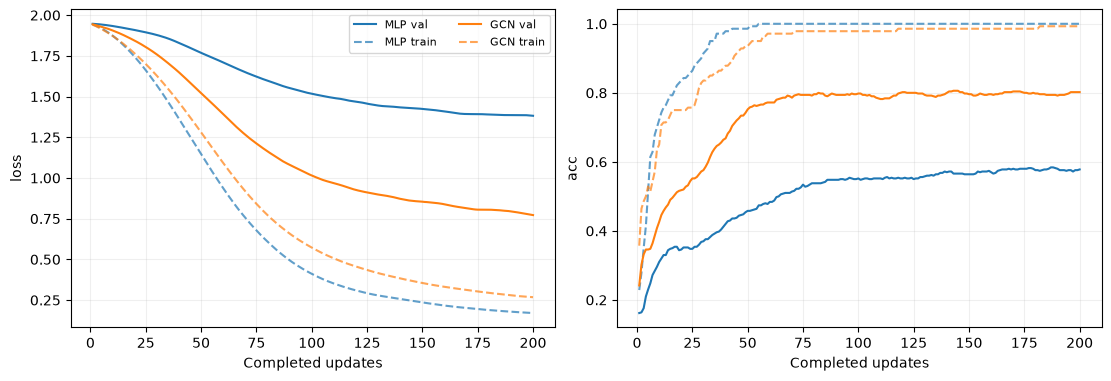

In [9]:
records = {}
label_sets = {20: train_idx}
operators = {
    ("MLP", 1.0): identity_operator(len(y)).to(DEVICE),
    ("GCN", 1.0): operator_full,
}
graph_versions = {1.0: edges_cpu}


def train_case(spec):
    assert spec["model"] in {"MLP", "GCN"}
    operator_key = (spec["model"], spec["keep"])
    if operator_key not in operators:
        new_edges = retain_undirected_edges(
            edges_cpu, len(y), spec["keep"], CONFIG["edge_seed"]
        )
        graph_versions[spec["keep"]] = new_edges
        operators[operator_key] = normalized_operator(new_edges, len(y)).to(DEVICE)
    active = label_sets[spec["labels"]]
    assert not torch.isin(active, torch.cat([val_idx, test_idx])).any()
    for seed in CONFIG["seeds"]:
        key = f"{case_key(spec)}_s{seed}"
        if key in records:
            continue  # 相同方案只训练一次，Q5/Q6 复用主基线。
        print(key, flush=True)
        run = fit_model(
            make_model(seed),
            x,
            operators[operator_key],
            active,
            y[active],
            val_idx,
            y[val_idx],
            epochs=CONFIG["epochs"],
            lr=CONFIG["lr"],
            weight_decay=CONFIG["weight_decay"],
            log_every=0,
        )
        run.update(spec=dict(spec), seed=seed)
        records[key] = run
        print(
            "  best epoch:",
            run["best_epoch"],
            "val:",
            round(run["best_val_acc"], 4),
            "seconds:",
            round(run["elapsed_seconds"], 2),
        )


for model_name in ["MLP", "GCN"]:
    train_case(dict(model=model_name, labels=20, keep=1.0))
print_validation_table(records)
baseline_curves = {model: records[f"{model}_L20_E100_s42"] for model in ["MLP", "GCN"]}
fig = plot_history(baseline_curves)
plt.show()

In [ ]:
# Q4-A：普通打印验证结果，不需要额外的显示工具。
baseline_summary_ref = summarize_cases(records)
print("Q4-A：比较验证表现")
for name_ref in ["MLP", "GCN"]:
    items_ref = [r for r in records.values() if r["spec"] == dict(model=name_ref, labels=20, keep=1.0)]
    score_ref = baseline_summary_ref[f"{name_ref}_L20_E100"]
    gaps_ref = [r["history"][r["best_epoch"]-1]["train_acc"] - r["best_val_acc"] for r in items_ref]
    print(name_ref, "验证均值:", round(score_ref["mean"],4),
          "标准差:", round(score_ref["sample_std"],4),
          "训练与验证的平均差距:", round(float(np.mean(gaps_ref)),4),
          "参数量:", items_ref[0]["parameters"]["trainable"])
baseline_delta_ref = (baseline_summary_ref["GCN_L20_E100"]["mean"] - baseline_summary_ref["MLP_L20_E100"]["mean"])*100
print("GCN−MLP:", round(baseline_delta_ref,2), "个百分点")
print("两模型只改变传播算子；结果描述当前图和配置，不能推广到所有图任务。")

Q4-A：比较验证表现
MLP 验证均值: 0.603 标准差: 0.0269 训练与验证的平均差距: 0.397 参数量: 23040
GCN 验证均值: 0.813 标准差: 0.0099 训练与验证的平均差距: 0.1691 参数量: 23040
GCN−MLP: 21.0 个百分点
两模型只改变传播算子；结果描述当前图和配置，不能推广到所有图任务。


In [ ]:
print("Q4-B：最佳轮次与最后轮次")
for name_ref in ["MLP", "GCN"]:
    for seed_ref in CONFIG["seeds"]:
        run_ref = records[f"{name_ref}_L20_E100_s{seed_ref}"]
        print(name_ref, "种子:", seed_ref, "最佳轮次:", run_ref["best_epoch"],
              "最佳验证准确率:", round(run_ref["best_val_acc"],4),
              "最后一轮验证准确率:", round(run_ref["history"][-1]["val_acc"],4))
print("训练集分数不能替代验证表现；继续训练不保证验证准确率继续提高。")
print("根据验证集保存模型，不能只看训练分数或固定取最后一轮。")

Q4-B：最佳轮次与最后轮次
MLP 种子: 42 最佳轮次: 188 最佳验证准确率: 0.584 最后一轮验证准确率: 0.578
MLP 种子: 2026 最佳轮次: 199 最佳验证准确率: 0.622 最后一轮验证准确率: 0.62
GCN 种子: 42 最佳轮次: 145 最佳验证准确率: 0.806 最后一轮验证准确率: 0.802
GCN 种子: 2026 最佳轮次: 159 最佳验证准确率: 0.82 最后一轮验证准确率: 0.814
训练集分数不能替代验证表现；继续训练不保证验证准确率继续提高。
根据验证集保存模型，不能只看训练分数或固定取最后一轮。


In [ ]:
print("Q4-C：逐个种子的比较")
seed_deltas_ref = []
for seed_ref in CONFIG["seeds"]:
    mlp_acc_ref = records[f"MLP_L20_E100_s{seed_ref}"]["best_val_acc"]
    gcn_acc_ref = records[f"GCN_L20_E100_s{seed_ref}"]["best_val_acc"]
    difference_ref = (gcn_acc_ref - mlp_acc_ref)*100
    seed_deltas_ref.append(difference_ref)
    print("种子:",seed_ref,"MLP:",round(mlp_acc_ref,4),"GCN:",round(gcn_acc_ref,4),
          "GCN−MLP:",round(difference_ref,2),"个百分点")
print("两个种子下是否都由 GCN 领先:", all(d > 0 for d in seed_deltas_ref))
print("只报告最好一次会隐藏训练波动。两个初始化不足以证明普遍稳定。")

Q4-C：逐个种子的比较
种子: 42 MLP: 0.584 GCN: 0.806 GCN−MLP: 22.2 个百分点
种子: 2026 MLP: 0.622 GCN: 0.82 GCN−MLP: 19.8 个百分点
两个种子下是否都由 GCN 领先: True
只报告最好一次会隐藏训练波动。两个初始化不足以证明普遍稳定。


## Q5 · 研究一：标签稀缺

如果每一类能拿到的训练标签从 20 个减少到 10 个、5 个，MLP 和 GCN 会受到一样大的影响吗？先写下你的猜测：____。

补全下面的训练集合和实验方案，再运行代码。三个标签数量都从同一个训练池中取：5 个标签用到的节点也要出现在 10 个标签的集合里，10 个的集合又包含在 20 个的集合里。图、验证节点和测试节点保持不变；暂时没有使用标签的训练池节点仍留在图上，不参与损失，也不挪到验证或测试集。

运行后，把结果填入下表。“均值 ± 标准差”使用种子 42、2026 的两次结果，最后一列用 GCN 的验证均值减去 MLP 的验证均值，单位为百分点。

| 每类训练标签数 | 训练节点总数 | MLP 验证准确率（均值 ± 标准差） | GCN 验证准确率（均值 ± 标准差） | GCN−MLP（百分点） |
| --- | ---: | ---: | ---: | ---: |
| 5 | ____ | ____ | ____ | ____ |
| 10 | ____ | ____ | ____ | ____ |
| 20 | ____ | ____ | ____ | ____ |

填好后，从表里选至少两组数值，说说哪种模型受标签减少的影响更大，是否与你的猜测一致：____。

再想一想：如果每次改变标签数量时，都把训练、验证和测试节点重新划分，比较里还会混入什么变化？____。


**Q5 假设与划分参考**

假设：增加训练标签通常有助于分类，图传播可能在更少标签时提供较大的补充收益；趋势需要实测，不预设严格单调。
改变每类可用标签数，固定训练池、全图、验证与测试节点、预处理和优化配置。
每类只随机排序一次，再取前 5、10、20 个，所以训练集合嵌套；未启用训练池节点不参与损失，也不移动到评价集合。

In [13]:
def nested_train_sets(pool, labels, seed=2026):
    # pool 是固定训练池的节点下标；labels 是按全图下标排列的真实标签。
    generator = torch.Generator().manual_seed(seed)
    budgets = [5, 10, 20]
    pieces = {count: [] for count in budgets}
    for category in range(7):
        # Q5a.1：先看 labels[pool]，再从 pool 取出属于 category 的节点下标。
        # 注意返回的是节点下标，不是类别值；每类应有 20 个候选节点。
        candidates = pool[labels[pool] == category]
        assert candidates.shape == (20,)

        # 每类只打乱一次！三个预算必须从同一排列中截取前缀。
        order = torch.randperm(len(candidates), generator=generator)
        shuffled = candidates[order]
        for count in budgets:
            # Q5a.2：取打乱后前 count 个节点。5 标签集合应包含于 10 标签集合。
            selected = shuffled[:count]
            assert len(selected) == count
            pieces[count].append(selected)
    # 按类别拼接、排序的写法已提供；验证和测试集合完全不改动。
    return {count: torch.cat(parts).sort().values for count, parts in pieces.items()}


def label_experiment_plan():
    plan = []
    for count in [5, 10, 20]:
        for model_name in ["MLP", "GCN"]:
            # Q5b.1 / Q5b.2：将当前模型和标签预算填入方案。
            # 标签数量是这组实验的变量，因此图的保留比例固定为 1.0。
            plan.append({"model": model_name, "labels": count, "keep": 1.0})
    return plan


MLP_L5_E100_s42


  best epoch: 172 val: 0.426 seconds: 1.84
MLP_L5_E100_s2026


  best epoch: 190 val: 0.444 seconds: 1.81
GCN_L5_E100_s42


  best epoch: 174 val: 0.704 seconds: 1.9
GCN_L5_E100_s2026


  best epoch: 114 val: 0.754 seconds: 1.89
MLP_L10_E100_s42


  best epoch: 182 val: 0.49 seconds: 1.83
MLP_L10_E100_s2026


  best epoch: 152 val: 0.51 seconds: 1.79
GCN_L10_E100_s42


  best epoch: 182 val: 0.734 seconds: 1.96
GCN_L10_E100_s2026


  best epoch: 112 val: 0.764 seconds: 1.89
case                 val accuracy (mean ± sample std)  seeds
MLP_L20_E100           0.6030 ± 0.0269              2
GCN_L20_E100           0.8130 ± 0.0099              2
MLP_L5_E100            0.4350 ± 0.0127              2
GCN_L5_E100            0.7290 ± 0.0354              2
MLP_L10_E100           0.5000 ± 0.0141              2
GCN_L10_E100           0.7490 ± 0.0212              2


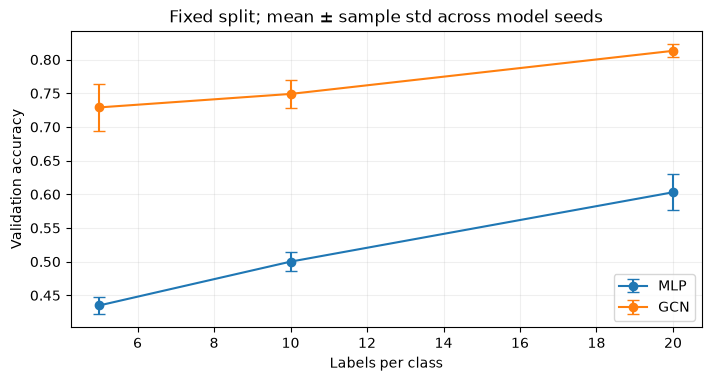

In [14]:
label_sets = nested_train_sets(train_idx, y, CONFIG["label_seed"])
assert set(label_sets) == {5, 10, 20}
for budget, indices in label_sets.items():
    assert torch.equal(torch.bincount(y[indices]), torch.full((7,), budget))
    assert torch.isin(indices, train_idx).all()
    assert not torch.isin(indices, torch.cat([val_idx, test_idx])).any()
assert torch.isin(label_sets[5], label_sets[10]).all()
assert torch.equal(label_sets[20], train_idx)
label_plan = label_experiment_plan()
assert {case_key(spec) for spec in label_plan} == {
    f"{model}_L{count}_E100" for model in ["MLP", "GCN"] for count in [5, 10, 20]
}
for spec in label_plan:
    train_case(spec)
print_validation_table(records)
fig = plot_factor(records, "labels")
plt.show()

In [ ]:
label_summary_ref = summarize_cases(records)
print("Q5 填表参考：以下均为验证结果")
for count_ref in [5,10,20]:
    mlp_ref = label_summary_ref[f"MLP_L{count_ref}_E100"]
    gcn_ref = label_summary_ref[f"GCN_L{count_ref}_E100"]
    print("每类标签:",count_ref,"训练节点:",len(label_sets[count_ref]))
    print("  MLP 均值:",round(mlp_ref["mean"],4),"标准差:",round(mlp_ref["sample_std"],4))
    print("  GCN 均值:",round(gcn_ref["mean"],4),"标准差:",round(gcn_ref["sample_std"],4))
    print("  GCN−MLP:",round((gcn_ref["mean"]-mlp_ref["mean"])*100,2),"个百分点")
for name_ref in ["MLP","GCN"]:
    gain_ref = (label_summary_ref[f"{name_ref}_L20_E100"]["mean"] - label_summary_ref[f"{name_ref}_L5_E100"]["mean"])*100
    print(name_ref,"从每类5到20标签的变化:",round(gain_ref,2),"个百分点")
print("如果每个预算都重划数据，还会改变训练和评价样本，不能单独归于标签数。")
print("结论仅针对这套固定嵌套样本、图和初始化，未覆盖所有标签抽样。")

Q5 填表参考：以下均为验证结果
每类标签: 5 训练节点: 35
  MLP 均值: 0.435 标准差: 0.0127
  GCN 均值: 0.729 标准差: 0.0354
  GCN−MLP: 29.4 个百分点
每类标签: 10 训练节点: 70
  MLP 均值: 0.5 标准差: 0.0141
  GCN 均值: 0.749 标准差: 0.0212
  GCN−MLP: 24.9 个百分点
每类标签: 20 训练节点: 140
  MLP 均值: 0.603 标准差: 0.0269
  GCN 均值: 0.813 标准差: 0.0099
  GCN−MLP: 21.0 个百分点
MLP 从每类5到20标签的变化: 16.8 个百分点
GCN 从每类5到20标签的变化: 8.4 个百分点
如果每个预算都重划数据，还会改变训练和评价样本，不能单独归于标签数。
结论仅针对这套固定嵌套样本、图和初始化，未覆盖所有标签抽样。


## Q6 · 研究二：引用关系缺失

假如只能拿到一部分论文引用记录，分类结果会怎样？还没运行前，你觉得引用越少，GCN 的准确率一定会下降吗？简单写下理由：____。

这次固定使用 GCN，每类仍有 20 个训练标签，只改变引用边的保留比例：100%、75%、50%。每条无向关系的两个方向要一起处理，所有节点和自环都保留。两个模型种子使用同一份缺失图。

补全删边函数和实验方案后运行。每张图都重新计算度数与归一化，再重新初始化模型、训练和评价。这里比较的是“拿到的引用数据不完整时重新训练”的效果。

将图的变化和验证结果一起填入下表。边数只统计无向引用关系，不包含自环；“没有外部邻居”指节点除自身外，已经没有其他节点与它相连。

| 引用保留比例 | 无向引用边数 | 没有外部邻居的节点数 | 连通分量数 | GCN 验证准确率（均值 ± 标准差） |
| --- | ---: | ---: | ---: | ---: |
| 100% | ____ | ____ | ____ | ____ |
| 75% | ____ | ____ | ____ | ____ |
| 50% | ____ | ____ | ____ | ____ |

表格填好后，引用至少两组数值，说说图的连接和分类结果分别发生了什么变化：____。如果两个种子的表现不同，要一起看，不能只挑符合猜测的一次。

最后，用 Q2 的小图说明：删去一条边后，如果只把原传播矩阵中的对应位置置零，却继续使用原来的度数，哪里会算错？____。


**Q6 假设与对照参考**

假设：引用缺失可能减少有用的传播路径，使 GCN 分类变差，但也可能移除干扰关系，因此不预设每次删边都使性能下降。
固定模型、标签、优化配置与评价节点，只改变可获得的引用关系；每张图重新计算度数并独立训练。
无向关系按同一乱序截取前缀，两个方向一起处理，自环和全部节点保留。

In [16]:
# Q6a：本函数从 lab_utils.py 移到此处，训练和绘图工具仍然直接提供。
# 目标：按无向关系抽取边，不能把一条关系的两个方向独立抽样。
def retain_undirected_edges(edges, n, keep=1.0, seed=2026):
    assert edges.device.type == "cpu" and 0 <= keep <= 1
    # Q6a.1：每条外部无向关系只取一次，并排除自环。
    # edges[0] 是接收下标，edges[1] 是发送下标；保留前者小于后者的位置。
    pairs = edges[:, edges[0] < edges[1]]
    # 固定一次随机排列；不同 keep 从同一顺序取前缀。
    generator = torch.Generator().manual_seed(seed)
    order = torch.randperm(pairs.shape[1], generator=generator)

    # Q6a.2：无向边总数乘 keep，取整数，即本次要保留多少条关系。
    count = int(pairs.shape[1] * keep)
    chosen = pairs[:, order[:count]]
    # Q6a.3：交换 chosen 的两行得到反向关系，列的顺序不需要改变。
    # 可用 chosen.flip(0)，也可以用行下标 [1,0]；请写出表达式。
    reverse = chosen.flip(0)
    # 补回双向关系与全部自环；去重、按固定顺序输出的细节已提供。
    result = torch.cat([chosen, reverse, self_edges(n)], dim=1)
    keys = (result[0] * n + result[1]).unique(sorted=True)
    return torch.stack((keys // n, keys % n))

In [17]:
# 先用 Q2 的小图验证，再运行 Cora 的缺失图训练。
kept_all = retain_undirected_edges(toy_edges, 5, keep=1.0)
kept_none = retain_undirected_edges(toy_edges, 5, keep=0.0)
kept_half = retain_undirected_edges(toy_edges, 5, keep=0.5)
assert torch.equal(kept_all, toy_edges)
assert torch.equal(kept_none, self_edges(5))
half_pairs = set(map(tuple, kept_half.T.tolist()))
assert all((j, i) in half_pairs for i, j in half_pairs)
assert all((i, i) in half_pairs for i in range(5))
assert kept_half.shape[1] == 2 * int(3 * 0.5) + 5
assert torch.equal(kept_half, retain_undirected_edges(toy_edges, 5, 0.5))
print("通过：无向抽样、保留数量、双向恢复、自环与固定随机种子检查。")

通过：无向抽样、保留数量、双向恢复、自环与固定随机种子检查。


In [18]:
def structure_experiment_plan():
    plan = []
    for fraction in [1.0, 0.75, 0.5]:
        # Q6b.1：只改变图的保留比例，模型与每类标签数保持固定。
        plan.append({"model": "GCN", "labels": 20, "keep": fraction})
    return plan


GCN_L20_E75_s42


  best epoch: 177 val: 0.772 seconds: 1.88
GCN_L20_E75_s2026


  best epoch: 161 val: 0.804 seconds: 1.86
GCN_L20_E50_s42


  best epoch: 176 val: 0.736 seconds: 1.87
GCN_L20_E50_s2026


  best epoch: 127 val: 0.766 seconds: 1.85
keep: 1.0 {'undirected_edges': 5278, 'isolates': 0, 'components': 78, 'largest_component': 2485}
keep: 0.75 {'undirected_edges': 3958, 'isolates': 182, 'components': 276, 'largest_component': 2245}
keep: 0.5 {'undirected_edges': 2639, 'isolates': 505, 'components': 668, 'largest_component': 1734}
case                 val accuracy (mean ± sample std)  seeds
MLP_L20_E100           0.6030 ± 0.0269              2
GCN_L20_E100           0.8130 ± 0.0099              2
MLP_L5_E100            0.4350 ± 0.0127              2
GCN_L5_E100            0.7290 ± 0.0354              2
MLP_L10_E100           0.5000 ± 0.0141              2
GCN_L10_E100           0.7490 ± 0.0212              2
GCN_L20_E75            0.7880 ± 0.0226              2
GCN_L20_E50            0.7510 ± 0.0212              2


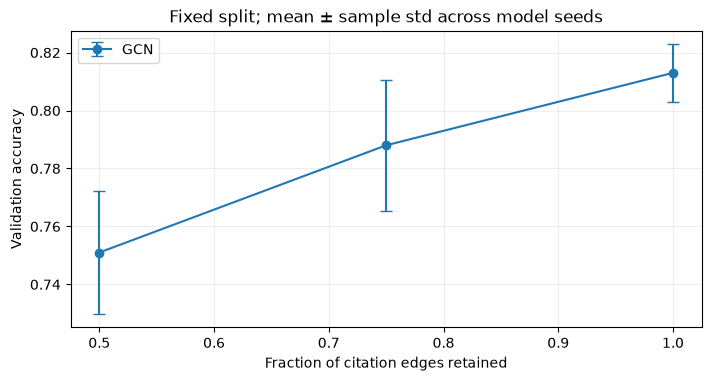

In [19]:
structure_plan = structure_experiment_plan()
assert {case_key(spec) for spec in structure_plan} == {
    "GCN_L20_E100",
    "GCN_L20_E75",
    "GCN_L20_E50",
}
for spec in structure_plan:
    train_case(spec)
for fraction, graph in sorted(graph_versions.items(), reverse=True):
    result = graph_audit(graph, len(y))
    print(
        "keep:",
        fraction,
        {
            k: result[k]
            for k in ["undirected_edges", "isolates", "components", "largest_component"]
        },
    )
assert len(records) == 8 * len(CONFIG["seeds"])
print_validation_table(records)
fig = plot_factor(records, "keep", models=("GCN",))
plt.show()

In [ ]:
structure_summary_ref = summarize_cases(records)
print("Q6 填表参考")
full_score_ref = structure_summary_ref["GCN_L20_E100"]["mean"]
for keep_ref in [1.0,0.75,0.5]:
    audit_ref = graph_audit(graph_versions[keep_ref],len(y))
    score_ref = structure_summary_ref[f"GCN_L20_E{round(keep_ref*100)}"]
    print("引用保留比例:",keep_ref,"无向边:",audit_ref["undirected_edges"],
          "无外部邻居节点:",audit_ref["isolates"],"连通分量:",audit_ref["components"])
    print("  验证均值:",round(score_ref["mean"],4),"标准差:",round(score_ref["sample_std"],4),
          "相对完整图变化:",round((score_ref["mean"]-full_score_ref)*100,2),"个百分点")
print("自环保留自身信息，但不能阻止外部连接消失或图分裂。")
print("每张缺失图都重新训练；这与在固定模型推理时删边不同。")
print("应报告全部种子，固定图上的两次初始化没有覆盖图抽样本身的波动。")

Q6 填表参考
引用保留比例: 1.0 无向边: 5278 无外部邻居节点: 0 连通分量: 78
  验证均值: 0.813 标准差: 0.0099 相对完整图变化: 0.0 个百分点
引用保留比例: 0.75 无向边: 3958 无外部邻居节点: 182 连通分量: 276
  验证均值: 0.788 标准差: 0.0226 相对完整图变化: -2.5 个百分点
引用保留比例: 0.5 无向边: 2639 无外部邻居节点: 505 连通分量: 668
  验证均值: 0.751 标准差: 0.0212 相对完整图变化: -6.2 个百分点
自环保留自身信息，但不能阻止外部连接消失或图分裂。
每张缺失图都重新训练；这与在固定模型推理时删边不同。
应报告全部种子，固定图上的两次初始化没有覆盖图抽样本身的波动。


In [ ]:
# Q6 小图解答：删除 0—1 后，仅将原 S 的对应两项置零是不够的。
keep_mask_ref = ~(((toy_edges[0] == 0) & (toy_edges[1] == 1)) |
                  ((toy_edges[0] == 1) & (toy_edges[1] == 0)))
reduced_edges_ref = toy_edges[:, keep_mask_ref]
wrong_s_ref = symmetric_op.clone()
wrong_s_ref[0, 1] = wrong_s_ref[1, 0] = 0
correct_s_ref = normalized_operator(reduced_edges_ref, 5).to_dense()
print("删边前含自环度数:", torch.bincount(toy_edges[0], minlength=5).tolist())
print("删边后含自环度数:", torch.bincount(reduced_edges_ref[0], minlength=5).tolist())
print("错误做法的自环系数:", wrong_s_ref.diag().tolist())
print("重新归一化的自环系数:", correct_s_ref.diag().tolist())
assert not torch.allclose(wrong_s_ref, correct_s_ref)
assert torch.allclose(correct_s_ref[0, 0], torch.tensor(0.5))
assert torch.allclose(correct_s_ref[1, 1], torch.tensor(1.0))
# 节点 0 的自环系数由 1/3 变为 1/2，节点 1 由 1/2 变为 1。
# 不仅被删边本身，剩余相邻边的系数也应随新度数改变。

删边前含自环度数: [3, 2, 3, 2, 1]
删边后含自环度数: [2, 1, 3, 2, 1]
错误做法的自环系数: [0.3333333134651184, 0.4999999701976776, 0.3333333134651184, 0.4999999701976776, 1.0]
重新归一化的自环系数: [0.4999999701976776, 1.0, 0.3333333134651184, 0.4999999701976776, 1.0]


## Q7 · 自己做一次调参

前面使用了一组给定参数。现在选一个你想研究的参数，先提出假设，再试着调整它。

| 可以调整的参数 | 原设置 | 可以尝试的值（也可以自己选） |
| --- | ---: | --- |
| 学习率 `lr` | 0.01 | 0.005、0.01、0.02 |
| 隐藏层宽度 `hidden` | 16 | 8、16、32 |
| 丢弃比例 `dropout` | 0.5 | 0.3、0.5、0.7 |

**先写下你的想法：** 我选择调整____。我猜____，因为____。

下面默认比较学习率。修改 `PARAM_NAME` 和 `PARAM_VALUES` 即可；一次只研究一个参数，候选值中保留原设置，方便比较。图、每类 20 个训练标签、训练轮数和两个随机种子都保持不变。

每个方案都从头训练。代码会直接打印每次运行的最佳轮次和验证准确率，并画出第一个种子的曲线。原设置已有运行结果，可以直接复用。

运行后记录各个值的验证均值与标准差，再回答：哪个设置更好？两个种子的结果是否一致？这次结果是否支持你的假设？如果没有，试着解释原因。这里用验证集比较参数即可。


**Q7 参考思路**

以默认学习率为例，可以先猜：较大学习率可能下降更快，但波动也可能更大；较小学习率在固定轮数下可能来不及学好。
运行后用曲线和两次验证结果判断，而不要求新值一定优于原设置。研究隐藏层宽度或 dropout 时也一次只改一个变量。

lr = 0.005 种子: 42 最佳轮次: 197 验证准确率: 0.8


lr = 0.005 种子: 2026 最佳轮次: 178 验证准确率: 0.82
两次结果的均值: 0.81 标准差: 0.0141

lr = 0.01 种子: 42 最佳轮次: 145 验证准确率: 0.806
lr = 0.01 种子: 2026 最佳轮次: 159 验证准确率: 0.82
两次结果的均值: 0.813 标准差: 0.0099



lr = 0.02 种子: 42 最佳轮次: 121 验证准确率: 0.82


lr = 0.02 种子: 2026 最佳轮次: 137 验证准确率: 0.822
两次结果的均值: 0.821 标准差: 0.0014

本节新训练次数: 4


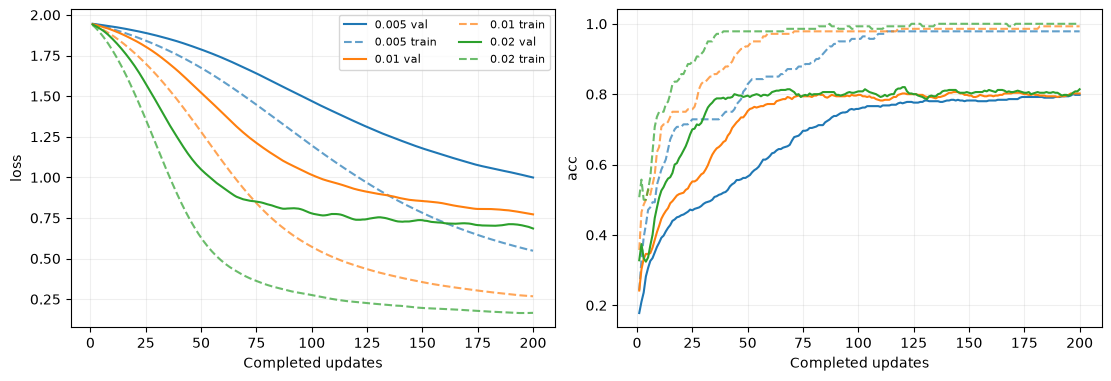

In [ ]:
# 只改下面两行，先研究一个参数。候选值需要包含原设置。
PARAM_NAME = "lr"  # 也可以选 "hidden" 或 "dropout"
PARAM_VALUES = [0.005, 0.01, 0.02]

assert PARAM_NAME in {"lr", "hidden", "dropout"}
assert CONFIG[PARAM_NAME] in PARAM_VALUES, "保留原设置，才能与新设置比较"
assert len(PARAM_VALUES) >= 2 and len(set(PARAM_VALUES)) == len(PARAM_VALUES)

tuning_runs = {}
tuning_results = {}
new_training_count = 0

for value in PARAM_VALUES:
    settings = CONFIG.copy()
    settings[PARAM_NAME] = value  # 只改这个参数，不改前面实验使用的 CONFIG。
    tuning_runs[value] = {}
    scores = []

    for seed in CONFIG["seeds"]:
        if value == CONFIG[PARAM_NAME]:
            run = records[f"GCN_L20_E100_s{seed}"]  # 复用原设置的基线。
        else:
            seed_everything(seed)
            model = GraphClassifier(
                hidden=settings["hidden"], dropout=settings["dropout"]
            ).to(DEVICE)
            run = fit_model(
                model, x, operator_full, train_idx, y[train_idx], val_idx, y[val_idx],
                epochs=settings["epochs"], lr=settings["lr"],
                weight_decay=settings["weight_decay"], log_every=0,
            )
            new_training_count += 1

        tuning_runs[value][seed] = run
        scores.append(run["best_val_acc"])
        print(PARAM_NAME, "=", value, "种子:", seed,
              "最佳轮次:", run["best_epoch"],
              "验证准确率:", round(run["best_val_acc"], 4))

    tuning_results[value] = {
        "val_mean": float(np.mean(scores)),
        "val_std": float(np.std(scores, ddof=1)),
    }
    print("两次结果的均值:", round(tuning_results[value]["val_mean"], 4),
          "标准差:", round(tuning_results[value]["val_std"], 4))
    print()

print("本节新训练次数:", new_training_count)
curves = {str(value): tuning_runs[value][CONFIG["seeds"][0]] for value in PARAM_VALUES}
fig = plot_history(curves)
plt.show()


In [ ]:
print("Q7 参考分析")
print("本次研究的参数:", PARAM_NAME, "原设置:", CONFIG[PARAM_NAME])
original_score_ref = tuning_results[CONFIG[PARAM_NAME]]["val_mean"]
for value_ref in PARAM_VALUES:
    result_ref = tuning_results[value_ref]
    print("参数值:",value_ref,"验证均值:",round(result_ref["val_mean"],4),
          "标准差:",round(result_ref["val_std"],4),
          "相对原设置变化:",round((result_ref["val_mean"]-original_score_ref)*100,2),"个百分点")
best_value_ref = max(PARAM_VALUES,key=lambda value:tuning_results[value]["val_mean"])
print("本次验证均值最高的参数值:",best_value_ref)
print("还要看两个种子的结果与曲线，不能只凭某一次训练判断。")
print("这些候选值和初始化数量有限，不能声称找到了最优参数。")

Q7 参考分析
本次研究的参数: lr 原设置: 0.01
参数值: 0.005 验证均值: 0.81 标准差: 0.0141 相对原设置变化: -0.3 个百分点
参数值: 0.01 验证均值: 0.813 标准差: 0.0099 相对原设置变化: 0.0 个百分点
参数值: 0.02 验证均值: 0.821 标准差: 0.0014 相对原设置变化: 0.8 个百分点
本次验证均值最高的参数值: 0.02
还要看两个种子的结果与曲线，不能只凭某一次训练判断。
这些候选值和初始化数量有限，不能声称找到了最优参数。
